# GridWorld: Tabular Q-Learning from Scratch with a Moving Obstacle

This notebook implements a 10 × 10 GridWorld with fixed walls and one obstacle that moves along a repeating path. A tabular Q-Learning agent learns to reach the goal while avoiding collisions. Both the environment and the Q-Learning algorithm are implemented from scratch.

## What this notebook covers

1. Specify the environment as a Markov Decision Process (MDP).
2. Implement the environment and tabular Q-Learning algorithm from scratch using NumPy.
3. Check the transition and episode-ending rules with assertions.
4. Train five agents with different random seeds.
5. Evaluate their greedy policies against a random-action policy.
6. Compare the learned policies with a Value Iteration planner.

## Scope

The grid, start, goal, and obstacle route are fixed throughout the experiments. Testing all eight initial obstacle phases checks whether the policies handle different timings of the same obstacle. It does not test performance on new maps or different start and goal positions.

Value Iteration is included as a planning reference. It uses the known transition model, so it is not another learned agent.

## 1. Environment specification

The environment is a 10 × 10 grid.

| Component | Definition |
|---|---|
| Start | `(0, 0)` |
| Goal | `(9, 9)` |
| Fixed obstacles | 8 predefined cells |
| Moving obstacle | 8-cell cyclic path along row 4 |
| Actions | Up, Down, Left, Right |
| State | `(agent_row, agent_col, obstacle_phase)` |
| Training start phase | `0` |
| Evaluation start phases | `0` through `7` |
| Episode time limit | 200 environment steps |

The phase is the index of the moving obstacle's current position in its cyclic path.

### Reward function

| Event | Reward |
|---|---:|
| Reach the goal | +100 |
| Collide with the moving obstacle | -10 |
| Attempt to enter a fixed wall or leave the grid | -5 |
| Make a valid non-terminal move | -1 |

### Order of events in one step

The agent first attempts its selected move. If the destination is outside the grid or contains a fixed wall, the agent stays in its current cell and receives the wall penalty. The obstacle then advances to the next phase. A collision is checked against the obstacle's new position. Reaching the goal or colliding with the moving obstacle ends the task episode.

The obstacle's position is determined by `phase`. Including that phase in the state is therefore necessary: with it, the current state and action determine the next state and reward.

### The 200-step limit

The step limit is treated as an external cutoff, not as a terminal state of the task. Q-Learning therefore keeps the next-state value in its target when an episode is truncated by the limit. The future-value term is removed only after reaching the goal or colliding with the moving obstacle.

This treatment is suitable when the limit is used to stop unusually long episodes. If the task itself were to reach the goal within 200 steps, the remaining number of steps would need to be part of the state.

In [1]:
%matplotlib inline

from IPython.display import display, HTML

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Keep notebook output readable and deterministic.
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.5.4
Pandas: 3.0.5


## 2. Configuration

The next cell defines the grid, obstacle positions, actions, rewards, and episode limit. `validate_configuration()` checks the basic map and action constraints before the environment is used.

In [2]:
# Environment dimensions and fixed positions
GRID_SIZE = 10
START = (0, 0)
GOAL = (9, 9)

FIXED_WALLS = {
    (1, 3), (2, 3), (3, 3),
    (5, 5), (6, 5), (7, 5),
    (7, 6), (7, 7),
}

# The moving obstacle occupies one cell at each phase, then repeats cyclically.
MOVING_OBSTACLE_PATH = [(4, col) for col in range(1, 9)]
N_PHASES = len(MOVING_OBSTACLE_PATH)

ACTIONS = {
    0: (-1, 0),  # Up
    1: (1, 0),   # Down
    2: (0, -1),  # Left
    3: (0, 1),   # Right
}
ACTION_NAMES = {
    0: "Up",
    1: "Down",
    2: "Left",
    3: "Right",
}
N_ACTIONS = len(ACTIONS)

GOAL_REWARD = 100.0
MOVING_COLLISION_REWARD = -10.0
WALL_COLLISION_REWARD = -5.0
STEP_REWARD = -1.0
MAX_STEPS = 200


def validate_configuration():
    """Fail early if the map or action definitions are inconsistent."""
    assert GRID_SIZE > 1
    assert len(ACTIONS) == 4
    assert set(ACTIONS) == set(ACTION_NAMES)
    assert START != GOAL

    def inside_grid(position):
        row, col = position
        return 0 <= row < GRID_SIZE and 0 <= col < GRID_SIZE

    assert inside_grid(START) and inside_grid(GOAL)
    assert START not in FIXED_WALLS and GOAL not in FIXED_WALLS
    assert all(inside_grid(position) for position in FIXED_WALLS)
    assert MOVING_OBSTACLE_PATH, "The moving-obstacle path cannot be empty."
    assert len(set(MOVING_OBSTACLE_PATH)) == len(MOVING_OBSTACLE_PATH)
    assert all(inside_grid(position) for position in MOVING_OBSTACLE_PATH)
    assert not (set(MOVING_OBSTACLE_PATH) & FIXED_WALLS)
    assert START not in MOVING_OBSTACLE_PATH
    assert GOAL not in MOVING_OBSTACLE_PATH
    assert MAX_STEPS > 0
    assert all(abs(dr) + abs(dc) == 1 for dr, dc in ACTIONS.values())


validate_configuration()

print(f"Grid: {GRID_SIZE} × {GRID_SIZE}")
print(f"Fixed obstacles: {len(FIXED_WALLS)}")
print(f"Moving-obstacle phases: {N_PHASES}")
print(f"Actions: {list(ACTION_NAMES.values())}")

Grid: 10 × 10
Fixed obstacles: 8
Moving-obstacle phases: 8
Actions: ['Up', 'Down', 'Left', 'Right']


## 3. Environment implementation

The environment follows a small Gymnasium-like interface:

- `reset(initial_phase=...)` returns the initial state.
- `step(action)` returns `(next_state, reward, terminated, truncated, info)`.
- `terminated=True` means the task reached a true terminal state (goal or collision).
- `truncated=True` means only the external step limit was reached.

The environment is deterministic. Randomness is introduced by the agent's exploration policy, not by the transition function.

In [3]:
class GridWorld:
    """Deterministic GridWorld with one cyclic moving obstacle."""

    def __init__(self, max_steps=MAX_STEPS):
        if not isinstance(max_steps, int) or max_steps <= 0:
            raise ValueError("max_steps must be a positive integer.")
        self.max_steps = max_steps
        self.reset()

    def reset(self, initial_phase=0):
        if not isinstance(initial_phase, (int, np.integer)):
            raise TypeError("initial_phase must be an integer.")
        if not 0 <= int(initial_phase) < N_PHASES:
            raise ValueError(f"initial_phase must be in [0, {N_PHASES - 1}].")

        self.agent_pos = START
        self.phase = int(initial_phase)
        self.steps = 0
        self._episode_over = False
        return self.get_state()

    def get_state(self):
        """Return (agent row, agent column, current obstacle phase)."""
        row, col = self.agent_pos
        return (row, col, self.phase)

    @property
    def moving_obstacle_pos(self):
        return MOVING_OBSTACLE_PATH[self.phase]

    def step(self, action):
        if self._episode_over:
            raise RuntimeError("Episode is over. Call reset() before another step.")
        if not isinstance(action, (int, np.integer)) or int(action) not in ACTIONS:
            raise ValueError(f"action must be one of {sorted(ACTIONS)}.")

        action = int(action)
        dr, dc = ACTIONS[action]
        row, col = self.agent_pos
        proposed_pos = (row + dr, col + dc)

        # 1) Agent moves if the proposed cell is valid; otherwise it stays put.
        if (
            0 <= proposed_pos[0] < GRID_SIZE
            and 0 <= proposed_pos[1] < GRID_SIZE
            and proposed_pos not in FIXED_WALLS
        ):
            self.agent_pos = proposed_pos
            reward = STEP_REWARD
            event = "move"
        else:
            reward = WALL_COLLISION_REWARD
            event = "wall_or_boundary"

        # 2) The obstacle advances after the agent's movement.
        self.phase = (self.phase + 1) % N_PHASES
        moving_pos = self.moving_obstacle_pos

        # 3) Detect task termination. Collision is checked before goal success.
        terminated = False
        if self.agent_pos == moving_pos:
            reward = MOVING_COLLISION_REWARD
            terminated = True
            event = "moving_obstacle_collision"
        elif self.agent_pos == GOAL:
            reward = GOAL_REWARD
            terminated = True
            event = "goal_reached"

        # 4) A time limit is a truncation, not a terminal transition.
        self.steps += 1
        truncated = (self.steps >= self.max_steps) and not terminated
        if truncated:
            event = "time_limit"

        self._episode_over = terminated or truncated

        info = {
            "agent_position": self.agent_pos,
            "moving_obstacle_position": moving_pos,
            "phase": self.phase,
            "steps": self.steps,
            "event": event,
        }
        return self.get_state(), float(reward), terminated, truncated, info

    def render(self, ax=None, title=None):
        """Render the current state. Returns the Matplotlib axes."""
        show_figure = ax is None
        if ax is None:
            fig, ax = plt.subplots(figsize=(6, 6))

        board = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int)
        for wall in FIXED_WALLS:
            board[wall] = 1

        cmap = ListedColormap(["#F4F4F4", "#424242"])
        ax.imshow(board, cmap=cmap, vmin=0, vmax=1, interpolation="none")

        # Grid lines
        ax.set_xticks(np.arange(-0.5, GRID_SIZE, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, GRID_SIZE, 1), minor=True)
        ax.grid(which="minor", color="white", linewidth=1.2)
        ax.tick_params(which="minor", bottom=False, left=False)

        # Start, goal, moving obstacle, and agent
        ax.scatter(*START[::-1], marker="s", s=100, color="#66BB6A", edgecolor="black", label="Start", zorder=4)
        ax.scatter(*GOAL[::-1], marker="*", s=220, color="#FFCA28", edgecolor="black", label="Goal", zorder=4)

        obstacle_row, obstacle_col = self.moving_obstacle_pos
        ax.scatter(obstacle_col, obstacle_row, marker="X", s=140, color="#EF5350", edgecolor="black", label="Moving obstacle", zorder=5)

        agent_row, agent_col = self.agent_pos
        ax.scatter(agent_col, agent_row, marker="o", s=110, color="#42A5F5", edgecolor="black", label="Agent", zorder=6)

        ax.set_xlim(-0.5, GRID_SIZE - 0.5)
        ax.set_ylim(GRID_SIZE - 0.5, -0.5)
        ax.set_aspect("equal")
        ax.set_xticks(range(GRID_SIZE))
        ax.set_yticks(range(GRID_SIZE))
        ax.set_xlabel("Column")
        ax.set_ylabel("Row")
        ax.set_title(title or f"GridWorld | phase={self.phase} | step={self.steps}")
        ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)

        if show_figure:
            plt.tight_layout()
            plt.show()
        return ax

## 4. Environment validation tests

These assertions test important edge cases before any training begins:

- reproducible transitions from the same state and action;
- invalid movement leaves the agent in place and advances the obstacle phase;
- a collision with the obstacle terminates the task;
- reaching the goal terminates successfully;
- the step limit truncates an episode and prevents further interaction until reset.

In [4]:
# Test 1: deterministic transition from the same state/action.
env_a = GridWorld()
env_b = GridWorld()
state_a, reward_a, term_a, trunc_a, info_a = env_a.step(3)  # Right
state_b, reward_b, term_b, trunc_b, info_b = env_b.step(3)
assert (state_a, reward_a, term_a, trunc_a, info_a["event"]) == (
    state_b, reward_b, term_b, trunc_b, info_b["event"]
)

# Test 2: attempting to move above the top boundary leaves the agent in place.
env = GridWorld()
state, reward, terminated, truncated, info = env.step(0)  # Up from (0, 0)
assert env.agent_pos == START
assert reward == WALL_COLLISION_REWARD
assert env.phase == 1
assert not terminated and not truncated

# Test 3: the agent moves into the cell that the obstacle occupies after advancing.
env = GridWorld()
env.agent_pos = (3, 2)  # A valid cell; phase 0 obstacle is at (4, 1).
state, reward, terminated, truncated, info = env.step(1)  # Down to (4, 2)
assert terminated and not truncated
assert info["event"] == "moving_obstacle_collision"
assert reward == MOVING_COLLISION_REWARD

# Test 4: reaching the goal is a successful terminal transition.
env = GridWorld()
env.agent_pos = (9, 8)
state, reward, terminated, truncated, info = env.step(3)  # Right to the goal
assert terminated and not truncated
assert info["event"] == "goal_reached"
assert reward == GOAL_REWARD

# Test 5: reaching max_steps is truncation, not task termination.
env = GridWorld(max_steps=1)
state, reward, terminated, truncated, info = env.step(1)  # Down
assert not terminated and truncated
assert info["event"] == "time_limit"
try:
    env.step(1)
    raise AssertionError("Stepping after truncation should have raised RuntimeError.")
except RuntimeError:
    pass

# Test 6: invalid action identifiers are rejected.
try:
    GridWorld().step(99)
    raise AssertionError("An invalid action should have raised ValueError.")
except ValueError:
    pass


# Test 7: the moving-obstacle phase wraps around after the final phase.
env = GridWorld()
env.reset(initial_phase=N_PHASES - 1)
state, reward, terminated, truncated, info = env.step(1)
assert env.phase == 0

# Test 8: invalid initial phases are rejected.
try:
    GridWorld().reset(initial_phase=N_PHASES)
    raise AssertionError("An out-of-range initial phase should have raised ValueError.")
except ValueError:
    pass

print("All 8 environment validation tests passed.")

All 8 environment validation tests passed.


## 5. Inspect the environment

The moving obstacle is shown at its current phase. The dashed route is the complete cyclic path it follows.

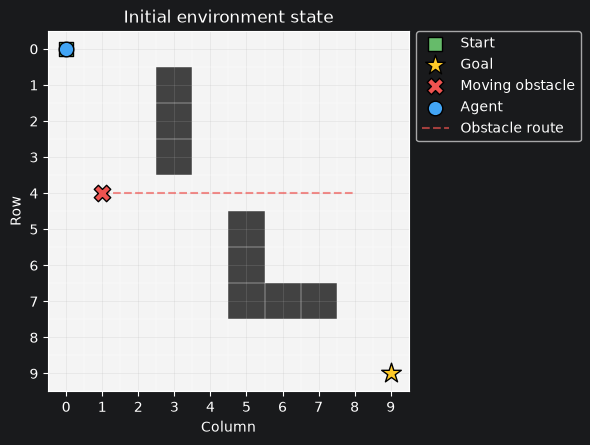

In [5]:
env = GridWorld()
fig, ax = plt.subplots(figsize=(6, 6))
env.render(ax=ax, title="Initial environment state")

# Overlay the complete moving-obstacle route for context.
route_cols = [position[1] for position in MOVING_OBSTACLE_PATH]
route_rows = [position[0] for position in MOVING_OBSTACLE_PATH]
ax.plot(route_cols, route_rows, "--", color="#EF5350", alpha=0.65, linewidth=1.5, label="Obstacle route")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
plt.tight_layout()
plt.show()

## 6. Tabular Q-Learning (From Scratch)

The Q-learning algorithm is implemented from scratch using NumPy, without relying on pre-built reinforcement learning algorithms or libraries.

The Q-table stores one value per `(row, column, phase, action)` combination. Its shape is:

$$
Q \in \mathbb{R}^{10 \times 10 \times 8 \times 4}
$$

The update is:

$$
Q(s,a) \leftarrow Q(s,a) +
\alpha \left[
r + \gamma \max_{a'} Q(s',a') - Q(s,a)
\right].
$$

For a true terminal transition (goal or moving-obstacle collision), the future-value term is zero. For a time-limit truncation, the next-state value is retained because the time limit is only an external cutoff.

An epsilon-greedy policy is used during training. At evaluation time, `epsilon = 0`; ties between equal Q-values are broken deterministically so results can be reproduced.

In [6]:
def compute_td_target(reward, next_q_values, terminated, gamma):
    """Compute a Q-learning target, bootstrapping across time-limit truncations."""
    if terminated:
        return float(reward)
    return float(reward) + gamma * float(np.max(next_q_values))


def choose_action(state, q_table, epsilon, rng, deterministic_ties=False):
    """Epsilon-greedy action selection."""
    if not 0.0 <= epsilon <= 1.0:
        raise ValueError("epsilon must be between 0 and 1.")

    if rng.random() < epsilon:
        return int(rng.integers(N_ACTIONS))

    q_values = q_table[state]
    best_actions = np.flatnonzero(q_values == np.max(q_values))

    if deterministic_ties:
        return int(best_actions[0])
    return int(rng.choice(best_actions))


def train_q_learning(
    seed,
    episodes=10_000,
    alpha=0.1,
    gamma=0.99,
    epsilon_start=1.0,
    epsilon_min=0.05,
    epsilon_decay=0.9995,
    max_steps=MAX_STEPS,
    initial_phase=0,
):
    """Train one independent Q-Learning agent and return its Q-table/history."""
    if episodes <= 0:
        raise ValueError("episodes must be positive.")
    if not 0 < alpha <= 1:
        raise ValueError("alpha must be in (0, 1].")
    if not 0 <= gamma <= 1:
        raise ValueError("gamma must be in [0, 1].")
    if not 0 <= epsilon_min <= epsilon_start <= 1:
        raise ValueError("Require 0 <= epsilon_min <= epsilon_start <= 1.")
    if not 0 < epsilon_decay <= 1:
        raise ValueError("epsilon_decay must be in (0, 1].")

    rng = np.random.default_rng(seed)
    env = GridWorld(max_steps=max_steps)
    q_table = np.zeros((GRID_SIZE, GRID_SIZE, N_PHASES, N_ACTIONS), dtype=np.float32)

    rewards = np.zeros(episodes, dtype=np.float32)
    steps_per_episode = np.zeros(episodes, dtype=np.int16)
    successes = np.zeros(episodes, dtype=np.int8)
    collisions = np.zeros(episodes, dtype=np.int8)
    timeouts = np.zeros(episodes, dtype=np.int8)
    epsilons = np.zeros(episodes, dtype=np.float32)

    epsilon = float(epsilon_start)

    for episode in range(episodes):
        state = env.reset(initial_phase=initial_phase)
        total_reward = 0.0
        final_event = None

        epsilons[episode] = epsilon

        for step_index in range(max_steps):
            action = choose_action(state, q_table, epsilon, rng)
            next_state, reward, terminated, truncated, info = env.step(action)

            # True terminal states do not bootstrap. Time-limit truncations do.
            td_target = compute_td_target(
                reward, q_table[next_state], terminated=terminated, gamma=gamma
            )

            td_error = td_target - q_table[state + (action,)]
            q_table[state + (action,)] += alpha * td_error

            total_reward += reward
            state = next_state
            final_event = info["event"]

            if terminated or truncated:
                break

        rewards[episode] = total_reward
        steps_per_episode[episode] = step_index + 1
        successes[episode] = int(final_event == "goal_reached")
        collisions[episode] = int(final_event == "moving_obstacle_collision")
        timeouts[episode] = int(final_event == "time_limit")

        epsilon = max(epsilon_min, epsilon * epsilon_decay)

    history = {
        "rewards": rewards,
        "steps": steps_per_episode,
        "successes": successes,
        "collisions": collisions,
        "timeouts": timeouts,
        "epsilons": epsilons,
    }
    return q_table, history


# Unit checks for the Q-table layout, action selector, and terminal/truncation targets.
_q_test = np.zeros((GRID_SIZE, GRID_SIZE, N_PHASES, N_ACTIONS), dtype=np.float32)
_rng_test = np.random.default_rng(123)
assert choose_action((0, 0, 0), _q_test, 1.0, _rng_test) in ACTIONS
assert choose_action((0, 0, 0), _q_test, 0.0, _rng_test, deterministic_ties=True) == 0
assert compute_td_target(-1.0, np.array([10.0, 0.0]), terminated=True, gamma=0.9) == -1.0
assert compute_td_target(-1.0, np.array([10.0, 0.0]), terminated=False, gamma=0.9) == 8.0
print("Q-Learning components and TD-target checks are ready.")

Q-Learning components and TD-target checks are ready.


## 7. Training with multiple seeds

Five agents are trained independently, using seeds `11`, `22`, `33`, `44`, and `55`. They share the same environment and hyperparameters, but their exploration sequences differ.

Every training episode starts at obstacle phase 0. The evaluation later tests each trained Q-table at all eight possible initial phases. This checks different starting timings of the obstacle without changing the map.

In [7]:
TRAINING_SEEDS = [11, 22, 33, 44, 55]
TRAINING_EPISODES = 5_000

TRAINING_PARAMETERS = {
    "alpha": 0.1,
    "gamma": 0.99,
    "epsilon_start": 1.0,
    "epsilon_min": 0.05,
    "epsilon_decay": 0.9995,
    "max_steps": MAX_STEPS,
    "initial_phase": 0,
}

q_tables = []
histories = []

for run_number, seed in enumerate(TRAINING_SEEDS, start=1):
    q_table, history = train_q_learning(
        seed=seed,
        episodes=TRAINING_EPISODES,
        **TRAINING_PARAMETERS,
    )
    q_tables.append(q_table)
    histories.append(history)
    print(
        f"Run {run_number}/{len(TRAINING_SEEDS)} | seed={seed} | "
        f"training success={history['successes'].mean() * 100:.1f}% | "
        f"mean return={history['rewards'].mean():.2f}"
    )

print("\nAll independent training runs completed.")

Run 1/5 | seed=11 | training success=81.5% | mean return=29.46
Run 2/5 | seed=22 | training success=84.8% | mean return=31.98
Run 3/5 | seed=33 | training success=83.6% | mean return=29.29
Run 4/5 | seed=44 | training success=84.2% | mean return=31.06
Run 5/5 | seed=55 | training success=83.9% | mean return=31.96

All independent training runs completed.


## 8. Training curves

The curves below show the **epsilon-greedy training behavior**, not the final greedy policy. Because exploration remains active during training, occasional failures are expected even after the Q-table has learned a useful route.

The solid line is the mean over independent seeds; the shaded region is ±1 standard deviation across seeds.

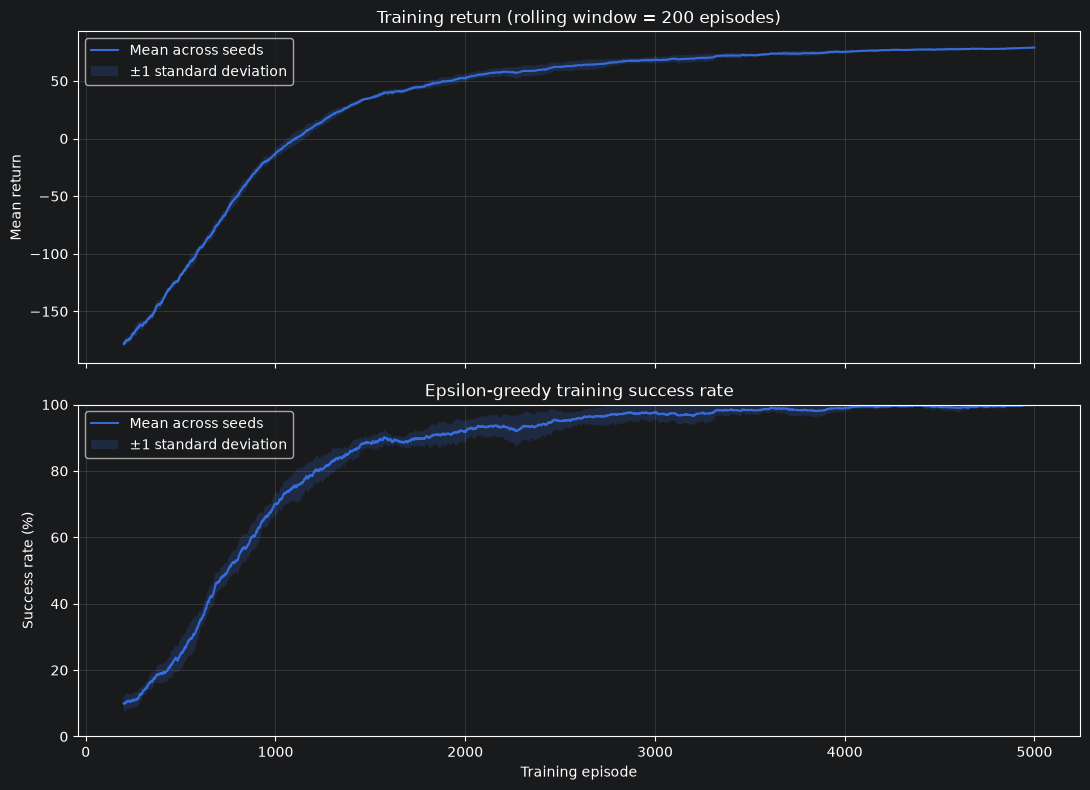

In [8]:
def rolling_mean(values, window):
    values = np.asarray(values, dtype=float)
    if window <= 0 or window > len(values):
        raise ValueError("window must be between 1 and the number of values.")
    return np.convolve(values, np.ones(window) / window, mode="valid")


WINDOW = 200
reward_curves = np.stack([rolling_mean(h["rewards"], WINDOW) for h in histories])
success_curves = np.stack([rolling_mean(h["successes"], WINDOW) * 100 for h in histories])
episode_axis = np.arange(WINDOW, TRAINING_EPISODES + 1)

reward_mean = reward_curves.mean(axis=0)
reward_std = reward_curves.std(axis=0, ddof=1)
success_mean = success_curves.mean(axis=0)
success_std = success_curves.std(axis=0, ddof=1)

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

axes[0].plot(episode_axis, reward_mean, label="Mean across seeds")
axes[0].fill_between(
    episode_axis, reward_mean - reward_std, reward_mean + reward_std,
    alpha=0.2, label="±1 standard deviation"
)
axes[0].set_ylabel("Mean return")
axes[0].set_title(f"Training return (rolling window = {WINDOW} episodes)")
axes[0].legend()

axes[1].plot(episode_axis, success_mean, label="Mean across seeds")
axes[1].fill_between(
    episode_axis, np.maximum(0, success_mean - success_std),
    np.minimum(100, success_mean + success_std),
    alpha=0.2, label="±1 standard deviation"
)
axes[1].set_xlabel("Training episode")
axes[1].set_ylabel("Success rate (%)")
axes[1].set_ylim(0, 100)
axes[1].set_title("Epsilon-greedy training success rate")
axes[1].legend()

plt.tight_layout()
plt.show()

## 9. Independent evaluation: greedy agent vs. random policy

Training results alone do not show how the final policy performs without exploration. Each trained Q-table is therefore evaluated with epsilon set to zero and deterministic tie-breaking.

### Evaluation protocol

- **Initial obstacle phases:** all eight phases, from `0` to `7`.
- **Q-Learning:** one greedy episode for each phase and each of the five trained Q-tables.
- **Random baseline:** 100 episodes per initial phase, with each action selected uniformly at random.
- **Shared conditions:** the same map, start, goal, rewards, and 200-step limit are used for both policies.

For Q-Learning, the results are first averaged over the eight phases for each trained agent, then summarized across the five seeds. For the random policy, the 100 trials are averaged within each phase; the phase-level means are then used in the comparison.

In [9]:
def run_evaluation_episode(q_table, initial_phase, policy="greedy", seed=0):
    """Run one episode and return metrics plus the state trajectory."""
    if policy not in {"greedy", "random"}:
        raise ValueError("policy must be 'greedy' or 'random'.")

    rng = np.random.default_rng(seed)
    env = GridWorld()
    state = env.reset(initial_phase=initial_phase)
    trajectory = [state]
    total_return = 0.0
    discounted_return = 0.0
    evaluation_gamma = TRAINING_PARAMETERS["gamma"]
    final_info = None

    for _ in range(env.max_steps):
        if policy == "random":
            action = int(rng.integers(N_ACTIONS))
        else:
            if q_table is None:
                raise ValueError("A Q-table is required for greedy evaluation.")
            action = choose_action(
                state, q_table, epsilon=0.0, rng=rng, deterministic_ties=True
            )

        next_state, reward, terminated, truncated, info = env.step(action)
        total_return += reward
        discounted_return += (evaluation_gamma ** (len(trajectory) - 1)) * reward
        state = next_state
        trajectory.append(state)
        final_info = info

        if terminated or truncated:
            break

    event = final_info["event"]
    return {
        "success": int(event == "goal_reached"),
        "collision": int(event == "moving_obstacle_collision"),
        "timeout": int(event == "time_limit"),
        "return": total_return,
        "discounted_return": discounted_return,
        "steps": len(trajectory) - 1,
        "event": event,
        "trajectory": trajectory,
    }


# Evaluate each trained policy on all eight initial obstacle phases.
greedy_records = []
for seed, q_table in zip(TRAINING_SEEDS, q_tables):
    for phase in range(N_PHASES):
        result = run_evaluation_episode(
            q_table, initial_phase=phase, policy="greedy", seed=seed * 100 + phase
        )
        greedy_records.append({
            "training_seed": seed,
            "initial_phase": phase,
            **{key: result[key] for key in ["success", "collision", "timeout", "return", "discounted_return", "steps", "event"]},
        })

greedy_results = pd.DataFrame(greedy_records)

# Evaluate a stochastic random-action baseline on the same phase scenarios.
RANDOM_TRIALS_PER_PHASE = 100
random_records = []
for phase in range(N_PHASES):
    for trial in range(RANDOM_TRIALS_PER_PHASE):
        result = run_evaluation_episode(
            None,
            initial_phase=phase,
            policy="random",
            seed=100_000 + phase * RANDOM_TRIALS_PER_PHASE + trial,
        )
        random_records.append({
            "initial_phase": phase,
            "trial": trial,
            **{key: result[key] for key in ["success", "collision", "timeout", "return", "discounted_return", "steps", "event"]},
        })

random_results = pd.DataFrame(random_records)

print(f"Greedy evaluation episodes: {len(greedy_results)}")
print(f"Random baseline episodes: {len(random_results)}")

Greedy evaluation episodes: 40
Random baseline episodes: 800


## 10. Evaluation results

The main success metric is computed from the independent greedy evaluation, not from the exploratory training episodes.

In [10]:
METRICS = ["success", "collision", "timeout", "return", "discounted_return", "steps"]

# Average the eight initial-phase scenarios within each independently trained agent.
greedy_by_seed = (
    greedy_results.groupby("training_seed")[METRICS]
    .mean()
    .reset_index()
)

# For the random policy, average repeated trials separately within each phase.
random_by_phase = (
    random_results.groupby("initial_phase")[METRICS]
    .mean()
    .reset_index()
)

# Summaries used in the final three-way comparison.
trained_mean = greedy_by_seed[METRICS].mean()
trained_std = greedy_by_seed[METRICS].std(ddof=1)
random_mean = random_by_phase[METRICS].mean()
random_phase_std = random_by_phase[METRICS].std(ddof=1)

trained_phase = (
    greedy_results.groupby("initial_phase")["success"].mean().mul(100)
)
random_phase = random_by_phase.set_index("initial_phase")["success"].mul(100)

phase_table = pd.DataFrame({
    "Initial obstacle phase": range(N_PHASES),
    "Q-Learning greedy success (%)": [trained_phase[p] for p in range(N_PHASES)],
    "Random policy success (%)": [random_phase[p] for p in range(N_PHASES)],
})

display(phase_table.round(1))

print("\nGreedy evaluation by training seed:")
display(greedy_by_seed.assign(
    success_pct=greedy_by_seed["success"] * 100,
    collision_pct=greedy_by_seed["collision"] * 100,
    timeout_pct=greedy_by_seed["timeout"] * 100,
)[["training_seed", "success_pct", "collision_pct", "timeout_pct", "return", "discounted_return", "steps"]].round(2))

,Initial obstacle phase,Q-Learning greedy success (%),Random policy success (%)
0,0,100.0,6.0
1,1,100.0,10.0
2,2,100.0,8.0
3,3,100.0,10.0
4,4,100.0,9.0
5,5,100.0,8.0
6,6,100.0,7.0
7,7,100.0,9.0



Greedy evaluation by training seed:


,training_seed,success_pct,collision_pct,timeout_pct,return,discounted_return,steps
0,11,100.0,0.0,0.0,80.38,65.23,19.12
1,22,100.0,0.0,0.0,79.25,63.71,19.75
2,33,100.0,0.0,0.0,79.62,63.98,19.88
3,44,100.0,0.0,0.0,79.00,63.32,20.00
4,55,100.0,0.0,0.0,81.50,66.77,18.50


## 11. Value Iteration as a planning reference

Because this environment is small, deterministic, and fully specified, we can compute its optimal state values using dynamic programming. This provides a stronger reference than a random policy.

The Bellman optimality update is:

$$
V_{k+1}(s)
=
\max_{a}
\left[
r(s,a)
+
\gamma
\left(1-\mathbb{1}_{\text{terminated}}\right)
V_k(s')
\right].
$$

The transition model is generated from the same `GridWorld.step` implementation, avoiding a second, potentially inconsistent definition of the dynamics.

Terminal transitions do not bootstrap. The external time-limit truncation is not part of this one-step transition model; the planning reference solves the underlying discounted MDP using the same `gamma` as Q-Learning.

**Interpretation:** This is a planning benchmark with access to the known transition model, not a learned RL agent. It is useful for measuring how closely Q-Learning approaches the optimal solution on this particular map.

In [11]:
DP_GAMMA = TRAINING_PARAMETERS["gamma"]
DP_TOLERANCE = 1e-10
DP_MAX_ITERATIONS = 10_000

# Build a deterministic one-step transition model from the actual environment.
# Arrays are indexed by [row, column, phase, action].
next_rows = np.zeros((GRID_SIZE, GRID_SIZE, N_PHASES, N_ACTIONS), dtype=np.int16)
next_cols = np.zeros_like(next_rows)
next_phases = np.zeros_like(next_rows)
transition_rewards = np.zeros((GRID_SIZE, GRID_SIZE, N_PHASES, N_ACTIONS), dtype=np.float64)
transition_terminated = np.ones((GRID_SIZE, GRID_SIZE, N_PHASES, N_ACTIONS), dtype=bool)
valid_states = np.ones((GRID_SIZE, GRID_SIZE, N_PHASES), dtype=bool)

model_env = GridWorld(max_steps=MAX_STEPS)
for row in range(GRID_SIZE):
    for col in range(GRID_SIZE):
        position = (row, col)
        for phase in range(N_PHASES):
            # Wall cells, the goal, and states already occupied by the obstacle
            # are not non-terminal decision states.
            if (
                position in FIXED_WALLS
                or position == GOAL
                or position == MOVING_OBSTACLE_PATH[phase]
            ):
                valid_states[row, col, phase] = False
                continue

            for action in range(N_ACTIONS):
                model_env.reset(initial_phase=phase)
                model_env.agent_pos = position
                next_state, reward, terminated, truncated, info = model_env.step(action)
                assert not truncated, "A one-step model transition should not hit the episode time limit."

                nr, nc, np_phase = next_state
                next_rows[row, col, phase, action] = nr
                next_cols[row, col, phase, action] = nc
                next_phases[row, col, phase, action] = np_phase
                transition_rewards[row, col, phase, action] = reward
                transition_terminated[row, col, phase, action] = terminated

# Synchronous Value Iteration.
value_function = np.zeros((GRID_SIZE, GRID_SIZE, N_PHASES), dtype=np.float64)
for dp_iteration in range(1, DP_MAX_ITERATIONS + 1):
    next_values = value_function[next_rows, next_cols, next_phases]
    q_values = transition_rewards + DP_GAMMA * (~transition_terminated) * next_values
    updated_values = np.max(q_values, axis=-1)
    updated_values[~valid_states] = 0.0

    max_delta = float(np.max(np.abs(updated_values[valid_states] - value_function[valid_states])))
    value_function = updated_values
    if max_delta < DP_TOLERANCE:
        break
else:
    raise RuntimeError("Value Iteration did not converge within DP_MAX_ITERATIONS.")

# Greedy policy induced by the converged optimal state values.
next_values = value_function[next_rows, next_cols, next_phases]
optimal_q_values = transition_rewards + DP_GAMMA * (~transition_terminated) * next_values
value_iteration_policy = np.argmax(optimal_q_values, axis=-1)


def run_value_iteration_episode(initial_phase):
    """Evaluate the deterministic planning policy on one initial phase."""
    env = GridWorld()
    state = env.reset(initial_phase=initial_phase)
    trajectory = [state]
    total_return = 0.0
    discounted_return = 0.0
    final_info = None

    for step_index in range(env.max_steps):
        action = int(value_iteration_policy[state])
        next_state, reward, terminated, truncated, info = env.step(action)
        total_return += reward
        discounted_return += (DP_GAMMA ** step_index) * reward
        state = next_state
        trajectory.append(state)
        final_info = info
        if terminated or truncated:
            break

    event = final_info["event"]
    return {
        "initial_phase": initial_phase,
        "success": int(event == "goal_reached"),
        "collision": int(event == "moving_obstacle_collision"),
        "timeout": int(event == "time_limit"),
        "return": total_return,
        "discounted_return": discounted_return,
        "steps": len(trajectory) - 1,
        "event": event,
        "trajectory": trajectory,
    }


planner_results = pd.DataFrame([
    run_value_iteration_episode(phase)
    for phase in range(N_PHASES)
])

assert len(planner_results) == N_PHASES
assert planner_results["event"].eq("goal_reached").all(), (
    "The planning reference did not reach the goal for every initial phase; inspect the model."
)

print(f"Value Iteration converged in {dp_iteration} sweeps (max delta={max_delta:.2e}).")
print(f"Non-terminal decision states represented: {int(valid_states.sum())}")
print("Optimal discounted value at the start state by phase:")
display(pd.DataFrame({
    "Initial phase": range(N_PHASES),
    "Optimal V(start, phase)": value_function[START[0], START[1], :],
}).round(4))
print("Planning-policy evaluation:")
display(planner_results[["initial_phase", "event", "success", "return", "discounted_return", "steps"]].round(3))
for result in planner_results.itertuples(index=False):
    expected_value = value_function[START[0], START[1], result.initial_phase]
    assert np.isclose(result.discounted_return, expected_value, atol=1e-8)


Value Iteration converged in 19 sweeps (max delta=0.00e+00).
Non-terminal decision states represented: 720
Optimal discounted value at the start state by phase:


,Initial phase,"Optimal V(start, phase)"
0,0,68.5886
1,1,68.5886
2,2,68.5886
3,3,68.5886
4,4,68.5886
5,5,68.5886
6,6,68.5886
7,7,68.5886


Planning-policy evaluation:


,initial_phase,event,success,return,discounted_return,steps
0,0,goal_reached,1,83.0,68.589,18
1,1,goal_reached,1,83.0,68.589,18
2,2,goal_reached,1,83.0,68.589,18
3,3,goal_reached,1,83.0,68.589,18
4,4,goal_reached,1,83.0,68.589,18
5,5,goal_reached,1,83.0,68.589,18
6,6,goal_reached,1,83.0,68.589,18
7,7,goal_reached,1,83.0,68.589,18


## 12. Comparing the three policies

The table compares the Q-Learning greedy policies with the Value Iteration planning policy and the random-action baseline.

- For Q-Learning, each seed is first averaged over the eight initial phases. The reported standard deviation is then calculated across the five trained agents.
- For Value Iteration, the standard deviation is calculated across the eight initial phases.
- For the random policy, the 100 trials are first averaged within each phase. The standard deviation is then calculated across the eight phase-level means.

Discounted return is the measure directly associated with the discount factor used by Q-Learning and Value Iteration. Mean return is the undiscounted sum of rewards in an episode.

In [12]:
planner_mean = planner_results[METRICS].mean()
planner_phase_std = planner_results[METRICS].std(ddof=1)


def metric_text(mean_value, std_value, percent=False):
    if percent:
        return f"{mean_value * 100:.1f}% ± {std_value * 100:.1f}%"
    return f"{mean_value:.2f} ± {std_value:.2f}"

comparison_rows = []
for label, mean_values, std_values, sd_basis in [
    ("Q-Learning (greedy)", trained_mean, trained_std, "across 5 training seeds"),
    ("Value Iteration (planning)", planner_mean, planner_phase_std, "across 8 initial phases"),
    ("Random policy", random_mean, random_phase_std, "across 8 initial-phase means"),
]:
    comparison_rows.append({
        "Policy": label,
        "Success rate": metric_text(mean_values["success"], std_values["success"], True),
        "Collision rate": metric_text(mean_values["collision"], std_values["collision"], True),
        "Timeout rate": metric_text(mean_values["timeout"], std_values["timeout"], True),
        "Mean return": metric_text(mean_values["return"], std_values["return"]),
        "Discounted return": metric_text(mean_values["discounted_return"], std_values["discounted_return"]),
        "Mean steps": metric_text(mean_values["steps"], std_values["steps"]),
        "SD basis": sd_basis,
    })

full_comparison = pd.DataFrame(comparison_rows)
display(full_comparison)

# The empirical gap to the planning reference is reported on discounted return.
optimal_discounted_return = float(planner_mean["discounted_return"])
learned_discounted_return = float(trained_mean["discounted_return"])
print(
    "Mean discounted-return gap to Value Iteration: "
    f"{optimal_discounted_return - learned_discounted_return:.3f}"
)

# Add the planner success rate to the per-phase table used below.
planner_phase = planner_results.set_index("initial_phase")["success"].mul(100)
phase_table["Value Iteration success (%)"] = [planner_phase[p] for p in range(N_PHASES)]
display(phase_table.round(1))

,Policy,Success rate,Collision rate,Timeout rate,Mean return,Discounted return,Mean steps,SD basis
0,Q-Learning (greedy),100.0% ± 0.0%,0.0% ± 0.0%,0.0% ± 0.0%,79.95 ± 1.01,64.60 ± 1.41,19.45 ± 0.63,across 5 training seeds
1,Value Iteration (planning),100.0% ± 0.0%,0.0% ± 0.0%,0.0% ± 0.0%,83.00 ± 0.00,68.59 ± 0.00,18.00 ± 0.00,across 8 initial phases
2,Random policy,8.4% ± 1.4%,71.6% ± 6.2%,20.0% ± 6.2%,-190.54 ± 14.67,-109.50 ± 5.50,108.09 ± 8.87,across 8 initial-phase means


Mean discounted-return gap to Value Iteration: 3.987


,Initial obstacle phase,Q-Learning greedy success (%),Random policy success (%),Value Iteration success (%)
0,0,100.0,6.0,100
1,1,100.0,10.0,100
2,2,100.0,8.0,100
3,3,100.0,10.0,100
4,4,100.0,9.0,100
5,5,100.0,8.0,100
6,6,100.0,7.0,100
7,7,100.0,9.0,100


### Interpreting the standard deviations

The standard deviations in the table do not all describe the same source of variation:

- **Q-Learning:** variation between five independently trained agents, after averaging each agent over the eight phases.
- **Value Iteration:** variation between the eight initial phases. The policy is deterministic, so this value is zero when all phases have the same result.
- **Random policy:** variation between the eight phase-level averages, each calculated from 100 random episodes. It is not the standard deviation across all 800 individual episodes.

The 100% success rates reported for the tested phases apply to this map and this obstacle route. They do not establish performance on different layouts.

## 13. Results by initial obstacle phase

This plot separates the evaluation results by starting phase. It shows the Q-Learning success rate across the five trained agents, alongside the Value Iteration and random-policy results for the same phases.

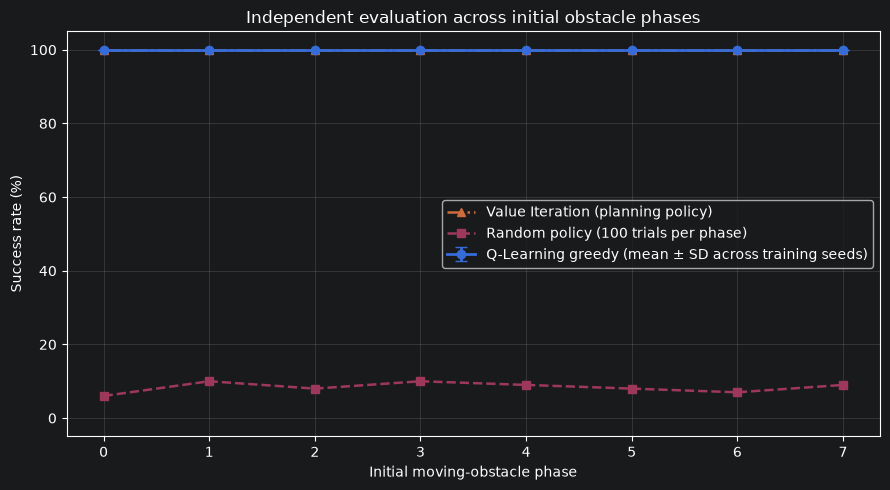

In [13]:
phase_x = np.arange(N_PHASES)
trained_success_mean = np.array([trained_phase[p] for p in phase_x])
trained_success_std = np.array([
    greedy_results[greedy_results["initial_phase"] == p]
    .groupby("training_seed")["success"].mean().std(ddof=1) * 100
    for p in phase_x
])
random_success_by_phase = np.array([random_phase[p] for p in phase_x])
planner_success_by_phase = np.array([planner_phase[p] for p in phase_x])

fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(
    phase_x, trained_success_mean,
    yerr=trained_success_std,
    marker="o", capsize=4, linewidth=2,
    label="Q-Learning greedy (mean ± SD across training seeds)",
)
ax.plot(
    phase_x, planner_success_by_phase,
    marker="^", linestyle="-.", linewidth=1.8,
    label="Value Iteration (planning policy)",
)
ax.plot(
    phase_x, random_success_by_phase,
    marker="s", linestyle="--", linewidth=1.8,
    label=f"Random policy ({RANDOM_TRIALS_PER_PHASE} trials per phase)",
)
ax.set_xticks(phase_x)
ax.set_ylim(-5, 105)
ax.set_xlabel("Initial moving-obstacle phase")
ax.set_ylabel("Success rate (%)")
ax.set_title("Independent evaluation across initial obstacle phases")
ax.legend()
plt.tight_layout()
plt.show()

## 14. Inspect a learned greedy trajectory

The following example uses the first trained agent and initial obstacle phase 0. This is a deterministic evaluation episode with exploration disabled.

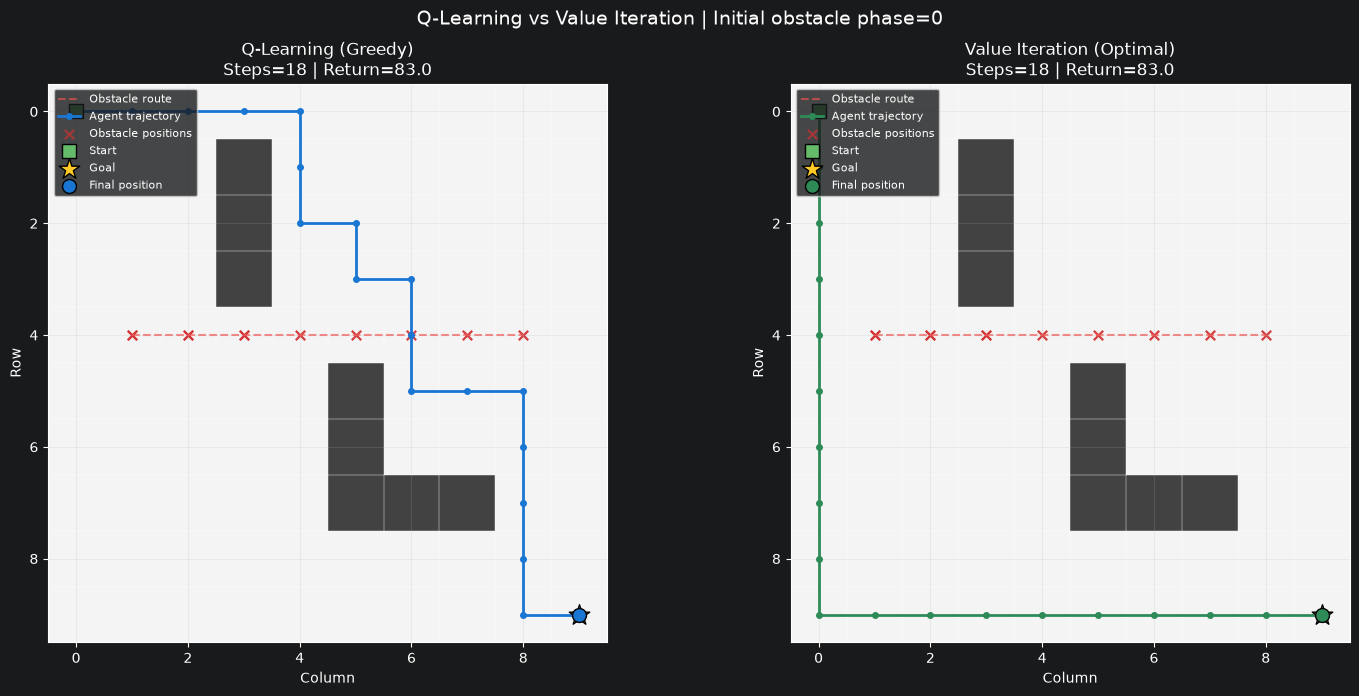

,Policy,success,collision,timeout,return,discounted_return,steps,event
0,Q-Learning,1,0,0,83.0,68.588639,18,goal_reached
1,Value Iteration,1,0,0,83.0,68.588639,18,goal_reached


In [19]:
DEMO_SEED_INDEX = 0
DEMO_PHASE = 0

# Q-Learning: first trained agent, greedy evaluation
q_demo_result = run_evaluation_episode(
    q_tables[DEMO_SEED_INDEX],
    initial_phase=DEMO_PHASE,
    policy="greedy",
    seed=999,
)

# Value Iteration: optimal planning policy
vi_demo_result = run_value_iteration_episode(
    initial_phase=DEMO_PHASE
)


def plot_trajectory(ax, trajectory, title, agent_color):
    board = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int)

    for wall in FIXED_WALLS:
        board[wall] = 1

    ax.imshow(
        board,
        cmap=ListedColormap(["#F4F4F4", "#424242"]),
        vmin=0,
        vmax=1,
        interpolation="none",
    )

    ax.set_xticks(np.arange(-0.5, GRID_SIZE, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, GRID_SIZE, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.2)
    ax.tick_params(which="minor", bottom=False, left=False)

    # Full cyclic path of the moving obstacle
    obstacle_cols = [p[1] for p in MOVING_OBSTACLE_PATH]
    obstacle_rows = [p[0] for p in MOVING_OBSTACLE_PATH]

    ax.plot(
        obstacle_cols,
        obstacle_rows,
        "--",
        color="#EF5350",
        alpha=0.65,
        label="Obstacle route",
    )

    # Agent trajectory
    agent_rows = [state[0] for state in trajectory]
    agent_cols = [state[1] for state in trajectory]

    ax.plot(
        agent_cols,
        agent_rows,
        "-o",
        color=agent_color,
        linewidth=2,
        markersize=4,
        label="Agent trajectory",
    )

    # Moving-obstacle positions during the episode
    moving_positions = [
        MOVING_OBSTACLE_PATH[state[2]]
        for state in trajectory
    ]

    ax.scatter(
        [p[1] for p in moving_positions],
        [p[0] for p in moving_positions],
        marker="x",
        s=45,
        color="#D32F2F",
        alpha=0.7,
        label="Obstacle positions",
    )

    # Start and Goal
    ax.scatter(
        *START[::-1],
        marker="s",
        s=110,
        color="#66BB6A",
        edgecolor="black",
        label="Start",
        zorder=5,
    )

    ax.scatter(
        *GOAL[::-1],
        marker="*",
        s=240,
        color="#FFCA28",
        edgecolor="black",
        label="Goal",
        zorder=5,
    )

    # Final agent position
    ax.scatter(
        agent_cols[-1],
        agent_rows[-1],
        marker="o",
        s=100,
        color=agent_color,
        edgecolor="black",
        label="Final position",
        zorder=6,
    )

    ax.set_xlim(-0.5, GRID_SIZE - 0.5)
    ax.set_ylim(GRID_SIZE - 0.5, -0.5)
    ax.set_aspect("equal")
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    ax.set_title(title)
    ax.legend(loc="upper left", fontsize=8)


# Plot both trajectories side by side
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

plot_trajectory(
    axes[0],
    q_demo_result["trajectory"],
    (
        f"Q-Learning (Greedy)\n"
        f"Steps={q_demo_result['steps']} | "
        f"Return={q_demo_result['return']:.1f}"
    ),
    agent_color="#1976D2",
)

plot_trajectory(
    axes[1],
    vi_demo_result["trajectory"],
    (
        f"Value Iteration (Optimal)\n"
        f"Steps={vi_demo_result['steps']} | "
        f"Return={vi_demo_result['return']:.1f}"
    ),
    agent_color="#2E8B57",
)

fig.suptitle(
    f"Q-Learning vs Value Iteration | Initial obstacle phase={DEMO_PHASE}",
    fontsize=14,
)

plt.tight_layout()
plt.show()


# Compare numerical results
comparison = pd.DataFrame(
    [
        {
            "Policy": "Q-Learning",
            **{
                key: q_demo_result[key]
                for key in [
                    "success", "collision", "timeout",
                    "return", "discounted_return", "steps", "event"
                ]
            },
        },
        {
            "Policy": "Value Iteration",
            **{
                key: vi_demo_result[key]
                for key in [
                    "success", "collision", "timeout",
                    "return", "discounted_return", "steps", "event"
                ]
            },
        },
    ]
)

display(comparison)

### Comparing the two trajectories

For this example, both policies reach the goal in 18 steps and receive a return of 83. Their routes are different, but their episode lengths and rewards are the same. This is consistent with the environment having more than one optimal route for this starting phase.

## 15. Trajectory animation

The next cell creates and displays an animation of the Q-Learning trajectory shown above. It updates the agent and moving-obstacle positions at each step. The animation is optional; the static trajectory plot contains the same route information.

In [18]:
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Circle, Rectangle


def animate_trajectory(trajectory, interval=350):
    if not trajectory:
        raise ValueError("trajectory cannot be empty.")
    if interval <= 0:
        raise ValueError("interval must be positive.")

    fig, ax = plt.subplots(figsize=(6, 6))
    board = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int)
    for wall in FIXED_WALLS:
        board[wall] = 1
    ax.imshow(board, cmap=ListedColormap(["#F4F4F4", "#424242"]), vmin=0, vmax=1)
    ax.set_xticks(np.arange(-0.5, GRID_SIZE, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, GRID_SIZE, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.2)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.set_xlim(-0.5, GRID_SIZE - 0.5)
    ax.set_ylim(GRID_SIZE - 0.5, -0.5)
    ax.set_aspect("equal")
    ax.scatter(*START[::-1], marker="s", s=100, color="#66BB6A", edgecolor="black", label="Start")
    ax.scatter(*GOAL[::-1], marker="*", s=220, color="#FFCA28", edgecolor="black", label="Goal")

    obstacle = Rectangle((-0.5, -0.5), 1, 1, color="#EF5350", alpha=0.8)
    agent = Circle((0, 0), radius=0.28, color="#1976D2", ec="black")
    ax.add_patch(obstacle)
    ax.add_patch(agent)
    trail, = ax.plot([], [], color="#1976D2", linewidth=2, alpha=0.7)
    status = ax.set_title("")
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)

    def update(frame):
        row, col, phase = trajectory[frame]
        agent.center = (col, row)
        obstacle_row, obstacle_col = MOVING_OBSTACLE_PATH[phase]
        obstacle.set_xy((obstacle_col - 0.5, obstacle_row - 0.5))
        trail.set_data(
            [state[1] for state in trajectory[:frame + 1]],
            [state[0] for state in trajectory[:frame + 1]],
        )
        status.set_text(f"Step {frame} | agent=({row}, {col}) | obstacle phase={phase}")
        return agent, obstacle, trail, status

    animation = FuncAnimation(
        fig, update, frames=len(trajectory), interval=interval,
        blit=True, repeat=False, cache_frame_data=False,
    )
    plt.close(fig)
    return HTML(animation.to_jshtml())

# Uncomment to display the demo animation:
display(animate_trajectory(q_demo_result["trajectory"]))

## 16. Save the trained Q-tables (optional)

The learned tables can be exported to a compressed NumPy archive. The seed names are preserved so the five independent runs can be identified later.

In [16]:
# Uncomment to save the learned policies in the current working directory:
# np.savez_compressed(
#     "basic_gridworld_q_tables.npz",
#     **{f"seed_{seed}": q for seed, q in zip(TRAINING_SEEDS, q_tables)},
# )

## 17. Conclusions and limitations

On this fixed GridWorld, all five trained Q-Learning agents reached the goal from each of the eight tested initial obstacle phases. The Value Iteration policy also reached the goal in all eight phases. The random policy performed much worse under the same episode rules.

Across the five trained agents, the mean discounted return was `64.60 ± 1.41`, compared with `68.59` for the Value Iteration policy. The learned policies therefore solved all of the tested episodes, but their average discounted return remained below the planning reference.

### Limitations

1. **One map:** training and evaluation use the same fixed obstacle layout.
2. **Known obstacle pattern:** the moving obstacle follows a deterministic, repeating route.
3. **One start and goal:** other start and goal positions are not tested.
4. **Tabular state representation:** the Q-table stores a separate value for each discrete state-action pair and would become impractical for much larger state spaces.
5. **Small environment:** these results apply to this compact GridWorld and should not be taken as evidence of performance on more complex tasks.
6. **Hyperparameter choice:** the learning rate, discount factor, and exploration schedule are fixed; no systematic tuning study is included.


In [17]:
# Final integrity checks for the executed notebook state.
assert len(q_tables) == len(TRAINING_SEEDS)
assert all(q.shape == (GRID_SIZE, GRID_SIZE, N_PHASES, N_ACTIONS) for q in q_tables)
assert len(greedy_results) == len(TRAINING_SEEDS) * N_PHASES
assert len(random_results) == N_PHASES * RANDOM_TRIALS_PER_PHASE
assert len(planner_results) == N_PHASES
assert set(greedy_results["event"]).issubset({"goal_reached", "moving_obstacle_collision", "time_limit"})
assert set(random_results["event"]).issubset({"goal_reached", "moving_obstacle_collision", "time_limit"})
assert set(planner_results["event"]) == {"goal_reached"}
assert np.all(np.isfinite(q_tables[0]))
assert np.all(np.isfinite(value_function[valid_states]))
print("All final integrity checks passed.")

All final integrity checks passed.
